In [ ]:
import tensorflow as tf
from tensorflow import keras

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
iris = load_iris()

X = iris.data
y = iris.target

print("Feature Shape:", X.shape)
print("Target Shape :", y.shape)

Feature Shape: (150, 4)
Target Shape : (150,)


In [ ]:
df = pd.DataFrame(X, columns=iris.feature_names)
df["Species"] = y

print("\nFirst Five Records:")
print(df.head())



First Five Records:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   Species  
0        0  
1        0  
2        0  
3        0  
4        0  


In [ ]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
Species              0
dtype: int64


In [ ]:
scaler = MinMaxScaler()
X = scaler.fit_transform(X)

print("\nFirst Five Scaled Records:")
print(X[:5])


First Five Scaled Records:
[[0.22222222 0.625      0.06779661 0.04166667]
 [0.16666667 0.41666667 0.06779661 0.04166667]
 [0.11111111 0.5        0.05084746 0.04166667]
 [0.08333333 0.45833333 0.08474576 0.04166667]
 [0.19444444 0.66666667 0.06779661 0.04166667]]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining Samples:", X_train.shape)
print("Testing Samples :", X_test.shape)


Training Samples: (120, 4)
Testing Samples : (30, 4)


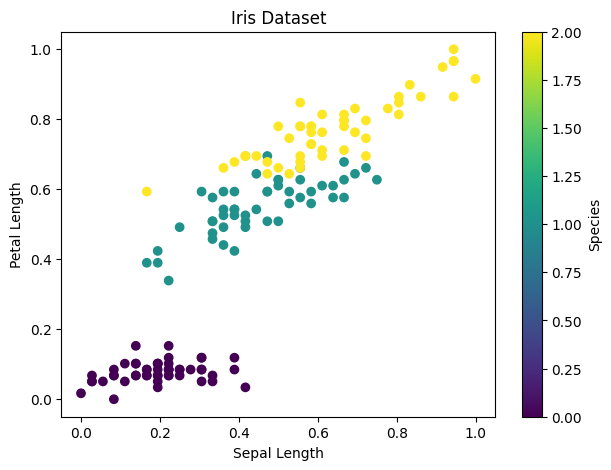

In [ ]:
plt.figure(figsize=(7,5))

plt.scatter(
    X[:,0],
    X[:,2],
    c=y,
    cmap="viridis"
)

plt.xlabel("Sepal Length")
plt.ylabel("Petal Length")
plt.title("Iris Dataset")
plt.colorbar(label="Species")

plt.show()

In [ ]:
model = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(3, activation="softmax")
])

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243 (972.00 B)

 Trainable params: 243 (972.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=8,
    validation_data=(X_test, y_test)
)


Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.3417 - loss: 1.1132 - val_accuracy: 0.3000 - val_loss: 1.1057
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3417 - loss: 1.0977 - val_accuracy: 0.3000 - val_loss: 1.0900
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.3417 - loss: 1.0806 - val_accuracy: 0.3000 - val_loss: 1.0741
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.3500 - loss: 1.0625 - val_accuracy: 0.3000 - val_loss: 1.0544
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4167 - loss: 1.0408 - val_accuracy: 0.4667 - val_loss: 1.0319
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5750 - loss: 1.0154 - val_accuracy: 0.5667 - val_loss: 1.0069
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.6667 - loss: 0.9897 - val_accuracy: 0.6333 - val_loss: 0.9803
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.6750 - loss: 0.9609 - val_accuracy: 0.6333 - v

In [ ]:
loss, accuracy = model.evaluate(X_test, y_test)

print("\nLoss :", loss)
print("Accuracy :", accuracy)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 109ms/step - accuracy: 0.9667 - loss: 0.2022

Loss : 0.20224282145500183
Accuracy : 0.9666666388511658


In [ ]:
predictions = model.predict(X_test)

predicted_class = np.argmax(predictions, axis=1)

print("\nPredicted Labels:")
print(predicted_class)

print("\nActual Labels:")
print(y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step

Predicted Labels:
[1 0 2 1 1 0 1 2 2 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Actual Labels:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


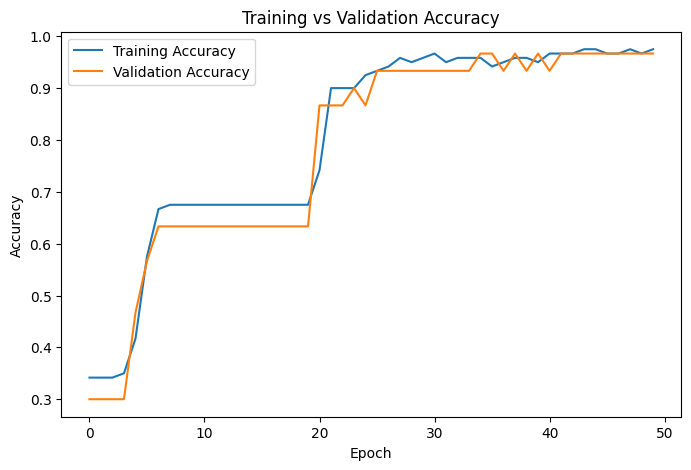

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.show()

In [ ]:
cm = confusion_matrix(y_test, predicted_class)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[10  0  0]
 [ 0  8  1]
 [ 0  0 11]]


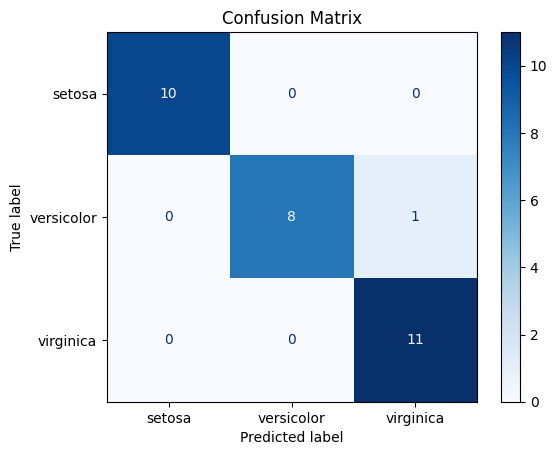

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix")

plt.show()